<a href="https://colab.research.google.com/github/SyuzannaKhalatyaning/CS156-Assignment/blob/main/assignment_1_photos/notebooks/CS156_First_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: install HEIC support (only needed if you have .heic files) and mount Drive
!pip install -q pillow-heif
from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 40.0 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
# Cell 2: find all images and count per class

from pathlib import Path
import pandas as pd

DATA_DIR = Path('/content/drive/MyDrive/data')

# folder name on Drive -> short label used in the model and report
FOLDERS = {
    'Work':        'work_study',
    'Socials':     'social',
    'Exploration': 'exploration',
}
EXTS = {'.jpg', '.jpeg', '.png', '.heic'}

rows = []
for folder, label in FOLDERS.items():
    for p in (DATA_DIR / folder).rglob('*'):   # rglob also finds photos in subfolders
        if p.suffix.lower() in EXTS:
            rows.append({'path': str(p), 'label': label})

df = pd.DataFrame(rows)
print(df['label'].value_counts())

label
exploration    230
work_study     188
social          71
Name: count, dtype: int64


In [3]:
for p in DATA_DIR.iterdir():
    print(repr(p.name), '| is_dir:', p.is_dir())

print()
for folder in FOLDERS:
    print(repr(folder), '-> exists:', (DATA_DIR / folder).exists())

'Socials' | is_dir: True
'Exploration' | is_dir: True
'Work' | is_dir: True
'labels_v1.csv' | is_dir: False

'Work' -> exists: True
'Socials' -> exists: True
'Exploration' -> exists: True


In [4]:
import re
from PIL import Image
import pillow_heif
pillow_heif.register_heif_opener()

def get_date(path):
    # 1) try EXIF
    try:
        exif = Image.open(path).getexif()
        d = exif.get_ifd(0x8769).get(36867) or exif.get(306)
        if d:
            return pd.to_datetime(d, format='%Y:%m:%d %H:%M:%S')
    except Exception:
        pass
    # 2) fall back to a date in the filename, e.g. 20260911_152838
    m = re.search(r'(20\d{6})[_-]?(\d{6})?', Path(path).name)
    if m:
        try:
            return pd.to_datetime(m.group(1), format='%Y%m%d')
        except Exception:
            pass
    return pd.NaT

df['date'] = df['path'].apply(get_date)
print(df['date'].isna().sum(), 'photos have no date')
print(df['date'].min(), '->', df['date'].max())
df = df.sort_values('date').reset_index(drop=True)

0 photos have no date
2024-08-07 13:25:33 -> 2026-10-12 21:51:16


In [5]:
df.to_csv('/content/drive/MyDrive/data/labels_v1.csv', index=False)

# **Splitting the Data**

In [6]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# 1) sort by time and build "sessions": a new session starts after a 2-hour gap
#After the first run I had 0 work-study photos in the validation, so in order to address this issue I changed the split to 15 minutes
df = df.sort_values('date').reset_index(drop=True)
df['session'] = (df['date'].diff() > pd.Timedelta(minutes=15)).cumsum()
print('Number of sessions:', df['session'].nunique())

groups = df['session']
y = df['label']

# 2) test set: roughly 1/7 of the data (about 14%)
outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(outer.split(df, y, groups))

# 3) validation set: roughly 1/6 of what remains (about 14% of the total)
trainval = df.iloc[trainval_idx]
inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(inner.split(trainval, trainval['label'], trainval['session']))

train = trainval.iloc[tr_idx]
val   = trainval.iloc[va_idx]
test  = df.iloc[test_idx]

# 4) check the result
for name, part in [('train', train), ('val', val), ('test', test)]:
    print(name, len(part))
    print(part['label'].value_counts(), '\n')

Number of sessions: 131
train 265
label
exploration    169
social          64
work_study      32
Name: count, dtype: int64 

val 174
label
work_study     150
exploration     23
social           1
Name: count, dtype: int64 

test 50
label
exploration    38
work_study      6
social          6
Name: count, dtype: int64 



# **Majority Class Baseline**

In [7]:
from sklearn.metrics import accuracy_score

CLASSES = sorted(df['label'].unique())          # fixed class order
label2id = {c: i for i, c in enumerate(CLASSES)}

majority = train['label'].mode()[0]
print('Classes:', CLASSES)
print('Majority class in train:', majority)
print('Baseline test accuracy:', round(accuracy_score(test['label'], [majority] * len(test)), 3))

Classes: ['exploration', 'social', 'work_study']
Majority class in train: exploration
Baseline test accuracy: 0.76


# Resize once and cache locally



In [10]:
!rm -rf /content/cache

In [11]:
from PIL import Image, ImageOps

IMG = 224
CACHE = Path('/content/cache')

def cache_split(part, name):
    out = []
    for i, r in enumerate(part.itertuples()):
        dst = CACHE / name / f'{i:04d}.jpg'
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = ImageOps.exif_transpose(Image.open(r.path)).convert('RGB').resize((IMG, IMG))
        img.save(dst, quality=95)
        out.append(str(dst))
    return out

train_paths = cache_split(train, 'train')
val_paths   = cache_split(val,   'val')
test_paths  = cache_split(test,  'test')

y_train = train['label'].map(label2id).values
y_val   = val['label'].map(label2id).values
y_test  = test['label'].map(label2id).values
print(len(train_paths), len(val_paths), len(test_paths))

265 174 50


# tf.data pipeline

In [12]:
import tensorflow as tf
tf.keras.utils.set_random_seed(42)      # reproducible results

def make_ds(paths, labels, training=False, batch=32):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        img.set_shape([IMG, IMG, 3])
        return tf.cast(img, tf.float32), y
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(len(paths), seed=42)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_paths, y_train, training=True)
val_ds   = make_ds(val_paths,   y_val)
test_ds  = make_ds(test_paths,  y_test)

# CNN from scratch

In [13]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((IMG, IMG, 3)),
    layers.Rescaling(1/255),                 # pixels to [0, 1]
    # augmentation (only active during training)
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    # 3 conv blocks: each looks for patterns, then shrinks the image
    layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(CLASSES))              # one score (logit) per class
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])
model.summary()

history = model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=5, restore_best_weights=True)])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.5925 - loss: 0.9607 - val_accuracy: 0.1322 - val_loss: 1.6162
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.6377 - loss: 0.8600 - val_accuracy: 0.1322 - val_loss: 1.6739
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.6377 - loss: 0.8054 - val_accuracy: 0.1322 - val_loss: 1.5043
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.6604 - loss: 0.7586 - val_accuracy: 0.1379 - val_loss: 1.3761
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.6868 - loss: 0.7279 - val_accuracy: 0.1379 - val_loss: 1.4758
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.7245 - loss: 0.7090 - val_accuracy: 0.1322 - val_loss: 1.3496
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.6679 - loss: 0.7166 - val_accuracy: 0.1379 - val_loss: 1.3806
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.7434 - loss: 0.6929 - val_accuracy: 0.1322 - val_loss: 1.3525
Epoch 9/

# Training curves

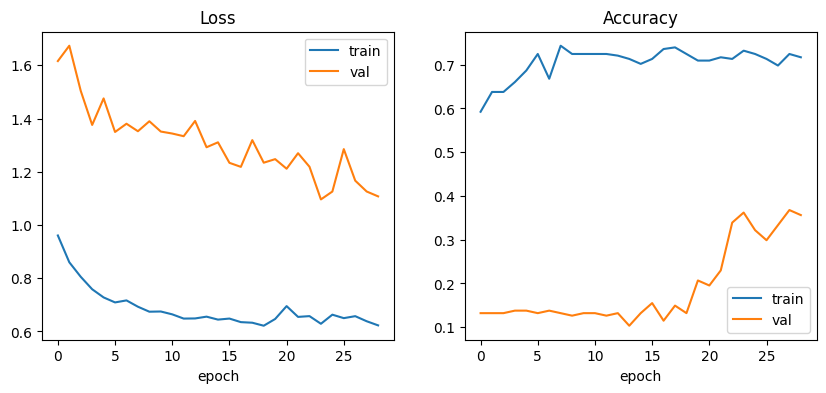

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history.history['loss'], label='train');     ax[0].plot(history.history['val_loss'], label='val');     ax[0].set_title('Loss')
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='val'); ax[1].set_title('Accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.show()

# **Cell 10: Test evaluation**

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 294ms/step
Test accuracy: 0.8
              precision    recall  f1-score   support

 exploration       0.80      0.97      0.88        38
      social       0.75      0.50      0.60         6
  work_study       0.00      0.00      0.00         6

    accuracy                           0.80        50
   macro avg       0.52      0.49      0.49        50
weighted avg       0.70      0.80      0.74        50



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


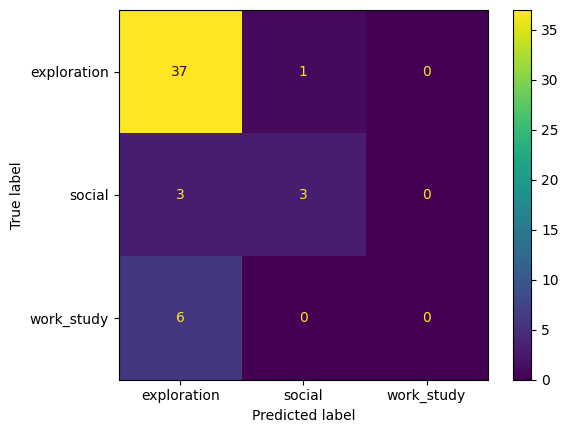

In [15]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = tf.nn.softmax(model.predict(test_ds), axis=1).numpy()
pred = probs.argmax(axis=1)

print('Test accuracy:', round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASSES).plot()
plt.show()

In [16]:
# Cell 11: load cached images and group labels
import numpy as np, pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_paths = train_paths + val_paths + test_paths
y_all = np.concatenate([y_train, y_val, y_test])
groups_all = np.concatenate([train['session'].values, val['session'].values, test['session'].values])
idx = np.arange(len(all_paths))
is_train = idx < len(train_paths)
is_val   = (idx >= len(train_paths)) & (idx < len(train_paths) + len(val_paths))
is_test  = idx >= len(train_paths) + len(val_paths)

X_img = np.stack([np.array(Image.open(p).convert('RGB')) for p in all_paths])  # uint8
print(X_img.shape)   # if you get KeyError 'session', rerun the session-based split cell

(489, 224, 224, 3)


In [17]:
# Cell 12: two feature sets
def color_feats(img, bins=8):
    f = [np.histogram(img[..., c], bins=bins, range=(0, 255), density=True)[0] for c in range(3)]
    f += [img.mean(axis=(0, 1)) / 255, img.std(axis=(0, 1)) / 255]
    return np.concatenate(f)
X_color = np.stack([color_feats(im) for im in X_img])

import tensorflow as tf
base = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False,
                                         weights='imagenet', pooling='avg')   # frozen feature extractor
X_emb = base.predict(tf.keras.applications.mobilenet_v2.preprocess_input(X_img.astype('float32')),
                     batch_size=32, verbose=0)
print(X_color.shape, X_emb.shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(489, 30) (489, 1280)


In [18]:
#cell 13
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def lr():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced'))

def fit_eval(model, X):
    p = model.fit(X[is_train], y_all[is_train]).predict(X[is_test])
    return accuracy_score(y_all[is_test], p), f1_score(y_all[is_test], p, average='macro')

rows = [
    ('Majority baseline',                        *fit_eval(DummyClassifier(strategy='most_frequent'), X_color)),
    ('Color histograms + logistic regression',   *fit_eval(lr(), X_color)),
    ('MobileNetV2 features + logistic regression', *fit_eval(lr(), X_emb)),
    ('Small CNN',                                accuracy_score(y_test, pred), f1_score(y_test, pred, average='macro')),
]
results = pd.DataFrame(rows, columns=['model', 'test accuracy', 'test macro-F1'])
print(results.round(3).to_string(index=False))

                                     model  test accuracy  test macro-F1
                         Majority baseline           0.76          0.288
    Color histograms + logistic regression           0.64          0.527
MobileNetV2 features + logistic regression           1.00          1.000
                                 Small CNN           0.80          0.494


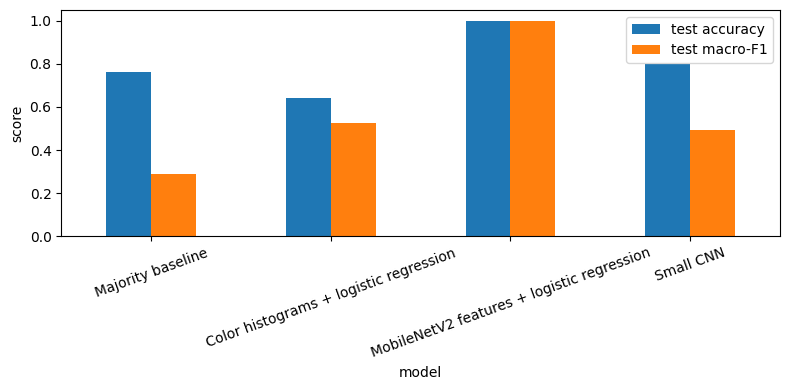

In [19]:
results.set_index('model')[['test accuracy', 'test macro-F1']].plot.bar(figsize=(8, 4), rot=20)
plt.ylim(0, 1.05); plt.ylabel('score'); plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()